In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/indrajeetmourya/delhi-metro-v2/delhi_metro_ridership_dataset_v2.csv


In [2]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

SEED = 42
np.random.seed(SEED)
sns.set_style("whitegrid"); plt.rcParams["figure.figsize"] = (10, 5)

In [3]:
df = pd.read_csv('/kaggle/input/datasets/indrajeetmourya/delhi-metro-v2/delhi_metro_ridership_dataset_v2.csv')
print(f'There are {df.shape[0]} rows and {df.shape[1]} columns')
df["Date"] = pd.to_datetime(df["Date"])
df = df.drop_duplicates().reset_index(drop = True)
print('After removing exact duplicates: ', df.shape)

#  - parking is a fixed station attribute  -> use that station's most common value
df["Parking_Available"] = df.groupby("Station_Name")["Parking_Available"].transform(
    lambda s: s.fillna(s.mode().iloc[0]))

#  - temperature / AQI are the same for every station on a day -> use that day's median
for c in ["Temperature_C", "AQI"]:
    df[c] = df.groupby("Date")[c].transform(lambda s: s.fillna(s.median()))
print("remaining NaNs in columns we use:", df[["Parking_Available", "Temperature_C", "AQI"]].isna().sum())

There are 35893 rows and 37 columns
After removing exact duplicates:  (35868, 37)
remaining NaNs in columns we use: Parking_Available    0
Temperature_C        0
AQI                  0
dtype: int64


## Data-leakage check
A column is only a valid input if we could know it before the footfall is observed. Anything that is a result of the day's ridership would let the model "cheat".

In [4]:
excluded = pd.DataFrame([
    ("Entry_Count, Exit_Count",                 "They add up to the target (Total = Entry + Exit)"),
    ("Peak_Hour_Footfall_Pct",                  "Describes the same day's ridership pattern — an outcome"),
    ("Delay_Minutes, Security_Incidents",       "Same-day operational outcomes, unknown in advance"),
    ("Avg_Fare_INR, Majority_Ticket_Type",      "Same-day outcomes; fare is just a copy of distance"),
    ("Record_ID, Date",                         "Identifiers — replaced by engineered calendar features"),
], columns=["Excluded column(s)", "Why"])
display(excluded)

,Excluded column(s),Why
0,"Entry_Count, Exit_Count",They add up to the target (Total = Entry + Exit)
1,Peak_Hour_Footfall_Pct,Describes the same day's ridership pattern — a...
2,"Delay_Minutes, Security_Incidents","Same-day operational outcomes, unknown in advance"
3,"Avg_Fare_INR, Majority_Ticket_Type",Same-day outcomes; fare is just a copy of dist...
4,"Record_ID, Date",Identifiers — replaced by engineered calendar ...


In [5]:

# Feature engineering (uses no target information)
df['Day_of_week_num'] = df['Date'].dt.dayofweek
df['Month_num'] = df['Date'].dt.month
df['Station_age'] = 2024 - df['Opening_Year']
df["Is_Offday"]  = ((df["Is_Weekend"] == 1) | (df["Is_Public_Holiday"] == 1)).astype(int)
df["Type_x_Daytype"] = df["Station_Type"] + " | " + df["Is_Offday"].astype(str)

numeric_cols = ["Distance_from_Connaught_Place_km", "Number_of_Platforms", "Escalator_Count", "Elevator_Count",
                "Temperature_C", "Rainfall_mm", "AQI",
                "Is_Weekend", "Is_Public_Holiday", "Is_Festival_Day", "Is_Offday",'Day_of_week_num','Month_num','Station_age']
category_cols = ["Station_Name", "Line", "Zone", "Station_Type", "Interchange_Station",
                 "Parking_Available", "Feeder_Bus_Available", "Weather_Condition",
                 "Event_Type", "Station_Status","Type_x_Daytype"]
    
print(f'{len(numeric_cols)} numeric features and {len(category_cols)} categorical features')

14 numeric features and 11 categorical features


## Preprocessing & Train / test split (by day)
Log of the target. Footfall is skewed (a few huge hubs) and effects are multiplicative (a weekend is about ×0.6 at every commuter station). Taking log1p(footfall) makes the pattern simpler. We train on the log value and convert predictions back with expm1.

A normal random split would put some stations of the same day in train and others in test. But every station on one day shares the same weather, AQI and festival, so the model would partly "see" the test day. Instead we split the days: 80 % of days for training, 20 % for testing.

In [6]:
X = pd.get_dummies(df[numeric_cols + category_cols], columns=category_cols, drop_first=True).astype(float)
y = df["Total_Footfall"]
y_log = np.log1p(y)

print("final feature matrix:", X.shape, "(rows, columns)")

final feature matrix: (35868, 161) (rows, columns)


In [7]:
all_days = df['Date'].drop_duplicates()
train_days, test_days = train_test_split(all_days, test_size = 0.2, random_state = SEED)
is_test = df['Date'].isin(test_days)

X_train, X_test = X[~is_test].copy(), X[is_test].copy()
y_train, y_test = y[~is_test].copy(), y[is_test].copy()
y_train_log = y_log[~is_test]

ss = StandardScaler()
X_train[numeric_cols] = ss.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = ss.transform(X_test[numeric_cols])

print(f'train: {len(X_train)} rows from {len(train_days)} days | test: {len(X_test)} rows from {len(test_days)}')
print('closed station rows in test', int((df.loc[is_test,'Station_Status'] == 'Closed').sum()))

train: 28616 rows from 292 days | test: 7252 rows from 74
closed station rows in test 1


## Baselines: simple guesses to beat

**Metrics we will use** (all in "riders"):
* **R²** — share of the variation explained (1.0 = perfect, 0 = no better than the average).
* **MAE** — average mistake in riders.
* **RMSE** — like MAE but punishes big mistakes more.
* **WAPE %** — total mistake ÷ total actual riders. 

In [8]:
def evaluate(name, y_true, y_pred):
    y_pred = np.clip(np.asarray(y_pred), 0, None)
    y_true = np.asarray(y_true)
    return {
        'Model': name,
        'R2': r2_score(y_true,y_pred),
        'MAE': mean_absolute_error(y_true,y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true,y_pred)),
        'WAPE %': 100 * np.abs(y_true - y_pred).sum() / y_true.sum()
    }
    
results, preds, preds_log = [], {}, {}

# Baseline 1: always guess the overall average
p = np.full(len(y_test),y_train.mean())
results.append(evaluate('Baseline 1: overall average', y_test, p )); preds["Baseline 1: overall average"] = p 

# Baseline 2: each station's typical footfall on weekdays vs off-days (a smart 'no-ML' guess)
train_df, test_df = df[~is_test], df[is_test]
typical = (train_df.groupby(["Station_Name", "Line", "Is_Offday"])["Total_Footfall"].median().rename("typical").reset_index())
p = test_df.merge(typical, on=["Station_Name", "Line", "Is_Offday"], how="left")["typical"].fillna(y_train.median()).values
results.append(evaluate("Baseline 2: station typical value", y_test, p)); preds["Baseline 2: station typical value"] = p

pd.DataFrame(results).round(3)


,Model,R2,MAE,RMSE,WAPE %
0,Baseline 1: overall average,-0.004,9858.094,12287.920,55.400
1,Baseline 2: station typical value,0.925,2174.629,3365.841,12.221


## Train the models

In [9]:
models = {
    "Linear Regression (raw target)": (LinearRegression(), False),
    "Linear Regression (log target)": (LinearRegression(), True),
    "Ridge (log target)":             (Ridge(alpha=1.0), True),
    "Decision Tree":                  (DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=SEED), True),
    "Random Forest":                  (RandomForestRegressor(n_estimators=100, max_depth=18, min_samples_leaf=3,
                                                             max_features=0.5, random_state=SEED, n_jobs=-1), True),
    "Gradient Boosting":              (GradientBoostingRegressor(n_estimators=150, max_depth=4, learning_rate=0.1,
                                                                 subsample=0.8, random_state=SEED), True),
    "XGBoost":                        (XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8,
                                                    colsample_bytree=0.8, random_state=SEED, n_jobs=-1), True),
}

fitted = {}
for name, (model, use_log) in models.items():
    if use_log:
        model.fit(X_train, y_train_log)
        preds_log[name] = model.predict(X_test)
        p = np.expm1(preds_log[name])
    else:
        model.fit(X_train,y_train)
        p = model.predict(X_test)
    fitted[name], preds[name] = model, p 
    r = evaluate(name, y_test, p); results.append(r)
    print(f"{name:32s} R2 = {r['R2']:.4f}   MAE = {r['MAE']:7.0f}   WAPE = {r['WAPE %']:.2f}%")

Linear Regression (raw target)   R2 = 0.9512   MAE =    1782   WAPE = 10.02%
Linear Regression (log target)   R2 = 0.9622   MAE =    1508   WAPE = 8.48%
Ridge (log target)               R2 = 0.9617   MAE =    1511   WAPE = 8.49%
Decision Tree                    R2 = 0.9539   MAE =    1642   WAPE = 9.23%
Random Forest                    R2 = 0.9615   MAE =    1532   WAPE = 8.61%
Gradient Boosting                R2 = 0.9616   MAE =    1517   WAPE = 8.52%
XGBoost                          R2 = 0.9615   MAE =    1521   WAPE = 8.55%


## Combine models: a voting ensemble

In [10]:
members = ['Ridge (log target)', 'Random Forest', 'Gradient Boosting', 'XGBoost']
vote_log = np.mean([preds_log[m] for m in members],axis = 0)
preds['Voting ensemble'] = np.expm1(vote_log)
preds_log['Voting ensemble'] = vote_log
results.append(evaluate('Voting ensemble', y_test, preds['Voting ensemble']))
print(f"Voting ensemble: R2 = {r['R2']:.4f}   MAE = {r['MAE']:.0f}   WAPE = {r['WAPE %']:.2f}%")

Voting ensemble: R2 = 0.9615   MAE = 1521   WAPE = 8.55%


## Compare all models

,R2,MAE,RMSE,WAPE %
Model,,,,
Voting ensemble,0.963,1496.702,2371.708,8.411
Linear Regression (log target),0.962,1508.180,2383.721,8.476
Ridge (log target),0.962,1510.602,2401.304,8.489
Gradient Boosting,0.962,1516.640,2402.738,8.523
XGBoost,0.961,1521.397,2406.695,8.550
Random Forest,0.961,1532.281,2407.200,8.611
Decision Tree,0.954,1641.917,2632.053,9.227
Linear Regression (raw target),0.951,1782.293,2708.280,10.016
Baseline 2: station typical value,0.925,2174.629,3365.841,12.221


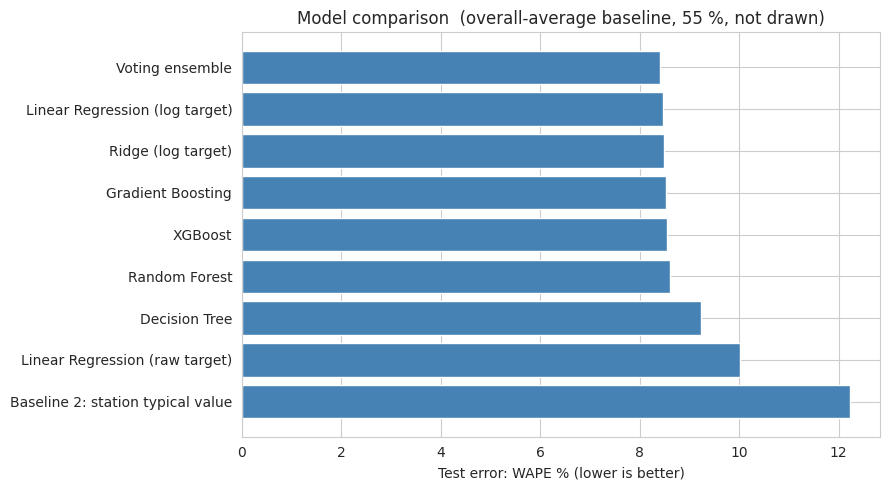

Best model on the test set: Voting ensemble


In [11]:
res = pd.DataFrame(results).set_index("Model").drop_duplicates()
display(res.sort_values("WAPE %").round(3))

plot_df = res.drop(index="Baseline 1: overall average").sort_values("WAPE %", ascending=False)   
plt.figure(figsize=(9, 5))
plt.barh(plot_df.index, plot_df["WAPE %"], color="steelblue")
plt.xlabel("Test error: WAPE % (lower is better)")
plt.title(f"Model comparison  (overall-average baseline, {res.loc['Baseline 1: overall average', 'WAPE %']:.0f} %, not drawn)")
plt.tight_layout(); plt.show()

best_name = res.drop(index=["Baseline 1: overall average", "Baseline 2: station typical value"])["WAPE %"].idxmin()
print("Best model on the test set:", best_name)

## Where does the best model go wrong?

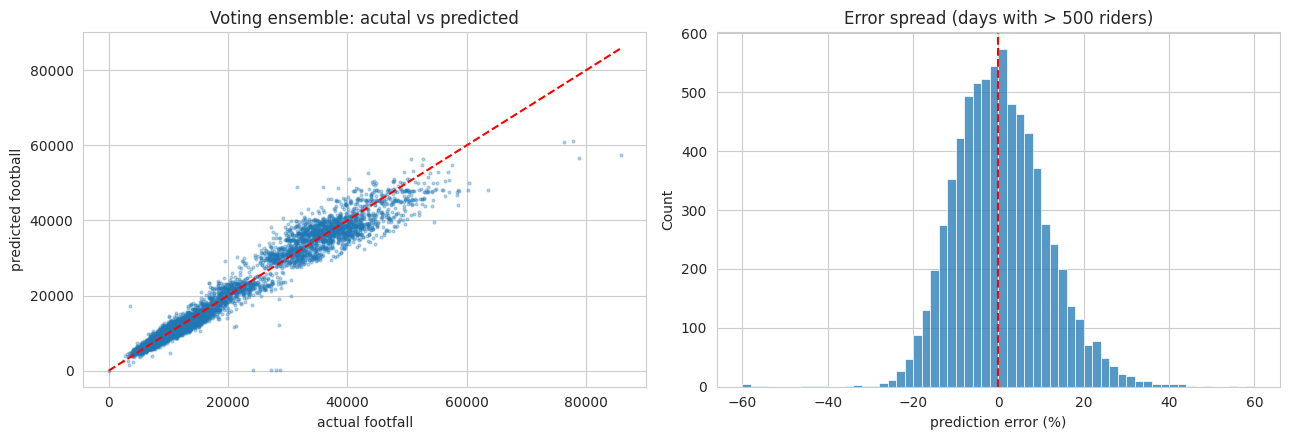

Closed-station rows in the test set (actual vs predicted):


,Date,Station_Name,Event_Type,Total_Footfall,Predicted
18942,2024-07-12,Najafgarh,Heavy Rain / Waterlogging,21,20.0


In [12]:
best_pred = preds[best_name]
test_view = test_df[["Date", "Station_Name", "Line", "Event_Type", "Station_Status", "Total_Footfall"]].copy()
test_view['Predicted'] = best_pred.round(0)
test_view["Error_%"] = 100 * (test_view["Predicted"] - test_view["Total_Footfall"]) / test_view["Total_Footfall"].clip(lower=1)

fig, ax = plt.subplots(1,2, figsize =(13,4.5))
ax[0].scatter(y_test, best_pred, s = 4, alpha = 0.3)
top = max(y_test.max(), best_pred.max())
ax[0].plot([0,top],[0,top], 'r--')
ax[0].set_xlabel('actual footfall')
ax[0].set_ylabel('predicted football')
ax[0].set_title(f'{best_name}: acutal vs predicted')

normal_rows = test_view[test_view["Total_Footfall"] > 500]
sns.histplot(normal_rows['Error_%'].clip(-60,60), bins = 60, ax=ax[1])
ax[1].axvline(0, color="r", ls="--")
ax[1].set_xlabel("prediction error (%)") 
ax[1].set_title("Error spread (days with > 500 riders)")
plt.tight_layout();plt.show()

print("Closed-station rows in the test set (actual vs predicted):")
display(test_view[test_view["Station_Status"] == "Closed"][["Date", "Station_Name", "Event_Type", "Total_Footfall", "Predicted"]])

## Unsupervised learning: K-Means on stations

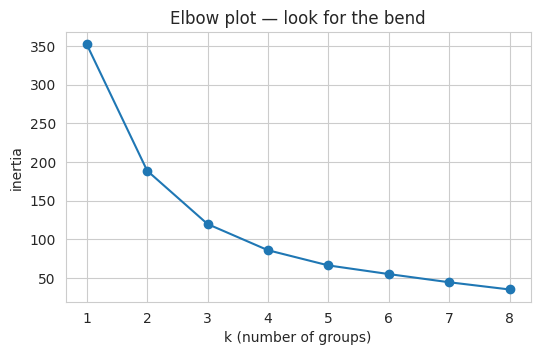

In [13]:
normal = train_df[train_df['Event_Type'] == 'Normal']
weekday = normal[normal['Is_Offday'] == 0].groupby('Station_Name')['Total_Footfall'].mean()
offday = normal[normal['Is_Offday'] == 1].groupby('Station_Name')['Total_Footfall'].mean()

profile = pd.DataFrame({
    "avg_footfall": normal.groupby("Station_Name")["Total_Footfall"].mean(),
    "offday_ratio": offday / weekday,
    "distance_km":  normal.groupby("Station_Name")["Distance_from_Connaught_Place_km"].first(),
    "platforms":    normal.groupby("Station_Name")["Number_of_Platforms"].first()}).dropna()

Z = StandardScaler().fit_transform(profile)

# Elbow plot: how much tighter do the groups get as k increases?
inertia = [KMeans(n_clusters = k, n_init = 10, random_state = SEED).fit(Z).inertia_ for k in range(1,9)]
plt.figure(figsize=(6, 3.5))
plt.plot(range(1, 9), inertia, "o-")
plt.xlabel("k (number of groups)") 
plt.ylabel("inertia")
plt.title("Elbow plot — look for the bend")
plt.show()

In [14]:
K = 4
profile["cluster"] = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(Z)
summary = profile.groupby("cluster").agg(stations=("avg_footfall", "size"), avg_footfall=("avg_footfall", "mean"),
                                         offday_ratio=("offday_ratio", "mean"), distance_km=("distance_km", "mean"),
                                         platforms=("platforms", "mean")).round(2)
display(summary.sort_values("avg_footfall", ascending=False))

# Example stations in each group
for c in summary.sort_values("avg_footfall", ascending=False).index:
    print(f"cluster {c}:", ", ".join(profile.index[profile['cluster'] == c][:6]), "...")

,stations,avg_footfall,offday_ratio,distance_km,platforms
cluster,,,,,
1,20,31771.28,0.65,8.65,3.50
2,12,12793.76,0.93,10.40,2.00
0,35,9883.75,0.58,9.99,2.00
3,21,9139.68,0.61,20.90,2.05


cluster 1: Azadpur, Botanical Garden, Central Secretariat, Hauz Khas, INA, Inderlok ...
cluster 2: Chandni Chowk, Delhi Aerocity, IGI Airport, Jama Masjid, Khan Market, Lal Quila ...
cluster 0: AIIMS, Akshardham, Anand Vihar, Ashok Park Main, Civil Lines, Dhaula Kuan ...
cluster 3: Badarpur Border, Bahadurgarh City, Delhi Cantt, Dilshad Garden, Dwarka, Dwarka Mor ...


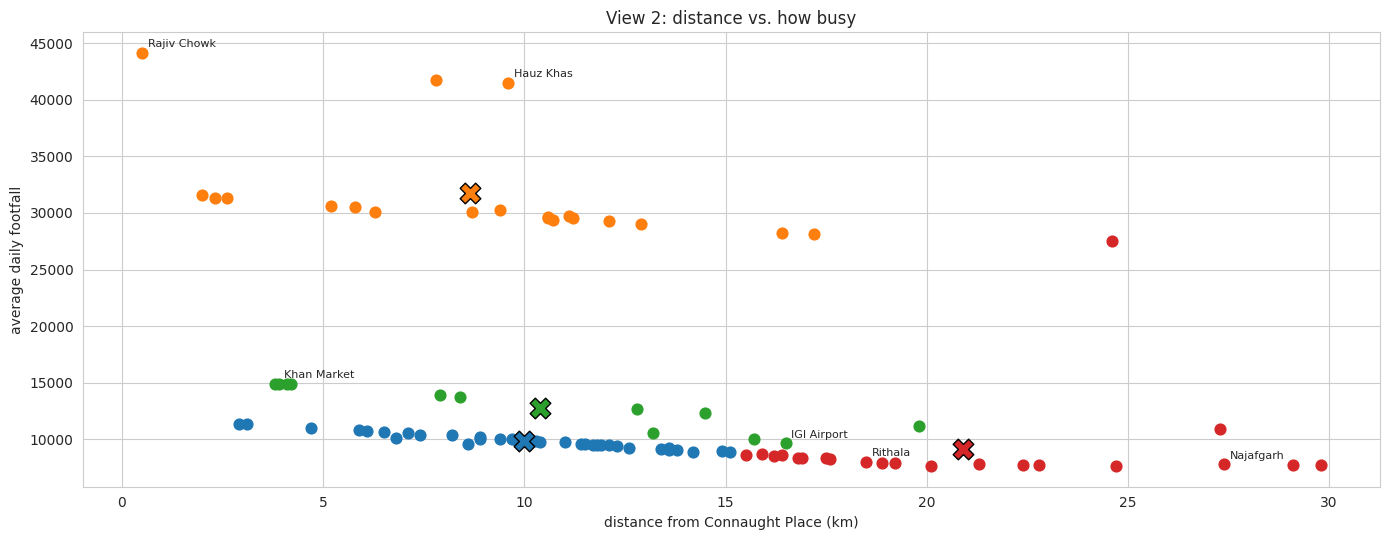

In [15]:
palette = sns.color_palette("tab10", K)
centres = profile.groupby("cluster")[["avg_footfall", "offday_ratio", "distance_km"]].mean()
label_these = ["Rajiv Chowk", "Khan Market", "Hauz Khas", "IGI Airport", "Rithala", "Najafgarh"]

plt.figure(figsize=(14, 5.5))
for c in sorted(profile["cluster"].unique()):
    g = profile[profile["cluster"] == c]
    plt.scatter(g["distance_km"], g["avg_footfall"], s=60, color=palette[c])
    plt.scatter(centres.loc[c, "distance_km"], centres.loc[c, "avg_footfall"], marker="X", s=220, color=palette[c], edgecolor="black")

for st in label_these:      # name a few stations so the picture is easy to read
    if st in profile.index:
        plt.annotate(st, (profile.loc[st, "distance_km"], profile.loc[st, "avg_footfall"]), fontsize=8, xytext=(4, 4), textcoords="offset points")

plt.xlabel("distance from Connaught Place (km)"); plt.ylabel("average daily footfall")
plt.title("View 2: distance vs. how busy")
plt.tight_layout(); plt.show()

In [16]:
ranked = res.sort_values('WAPE %')
print('Models ranked by test error (WAPE %)')
print(ranked[['R2','MAE','WAPE %']].round(3).to_string())
print()
print(f'Best Model: {best_name} -> R2 = {res.loc[best_name,'R2']:.3f}, Average mistake = {res.loc[best_name,'MAE']:,.0f} Rider per station-day = {res.loc[best_name,'WAPE %']:.1f}% of riders')
print(f"Simple 'station typical value' guess:  {res.loc['Baseline 2: station typical value', 'WAPE %']:.1f}%")
print(f"Linear regression raw vs log target:   {res.loc['Linear Regression (raw target)', 'WAPE %']:.1f}%  ->  {res.loc['Linear Regression (log target)', 'WAPE %']:.1f}%")

Models ranked by test error (WAPE %)
                                      R2       MAE  WAPE %
Model                                                     
Voting ensemble                    0.963  1496.702   8.411
Linear Regression (log target)     0.962  1508.180   8.476
Ridge (log target)                 0.962  1510.602   8.489
Gradient Boosting                  0.962  1516.640   8.523
XGBoost                            0.961  1521.397   8.550
Random Forest                      0.961  1532.281   8.611
Decision Tree                      0.954  1641.917   9.227
Linear Regression (raw target)     0.951  1782.293  10.016
Baseline 2: station typical value  0.925  2174.629  12.221
Baseline 1: overall average       -0.004  9858.094  55.400

Best Model: Voting ensemble -> R2 = 0.963, Average mistake = 1,497 Rider per station-day = 8.4% of riders
Simple 'station typical value' guess:  12.2%
Linear regression raw vs log target:   10.0%  ->  8.5%
